This notebook ('diann_peptide_overlap_analysis.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and analyzes peptide identification overlap both between conditions (pairwise and three-way) and between replicates within each condition.
Results are exported as individual .csv files (peptide lists, pairwise/replicate overlap tables) together with Venn diagrams and replicate overlap bar plots.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` and `peptide_overlap_analysis` modules, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment** – For each flush mode, map acquisition dates in the Run name to condition names.
7. **Per-condition peptide sets** – Build completeness-filtered peptide sets per condition and export them as peptide lists.
8. **Pairwise overlap** – For each condition pair, compute the peptide overlap and generate a two-way Venn diagram.
9. **Three-way overlap** – Compute three-way exclusive peptide sets across all conditions and generate a three-way Venn diagram.
10. **Replicate overlap** – For each condition, compute pairwise peptide overlap between replicates, export the combined overlap table, and plot a replicate overlap bar chart.
11. **Repeat for both flush modes** – The entire overlap analysis (steps 6–10) is run separately for forward and reverse flush data.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import dedent

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter
import peptide_overlap_analysis as overlap_ana

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']

Current working directory:
/z/user/Dennis/t

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/peptide_overlap_analysis/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse



============================== FORWARD FLUSH ==============================
  pepmap: 10880 complete peptides
  nanoshield_tht021_flip: 17233 complete peptides
  direct_injection: 26170 complete peptides
  Exported peptide_list_pepmap_forward.csv (10880 peptides)
  Exported peptide_list_nanoshield_tht021_flip_forward.csv (17233 peptides)
  Exported peptide_list_direct_injection_forward.csv (26170 peptides)

=== Pairwise overlap [forward]: pepmap vs direct_injection ===
  only pepmap: 460 | only direct_injection: 15750 | shared: 10420
  only_pepmap: 460 peptides -> overlap_pepmap_vs_direct_injection_only_pepmap_forward_peptides.csv
  only_direct_injection: 15750 peptides -> overlap_pepmap_vs_direct_injection_only_direct_injection_forward_peptides.csv
  shared_pepmap_direct_injection: 10420 peptides -> overlap_pepmap_vs_direct_injection_shared_pepmap_direct_injection_forward_peptides.csv


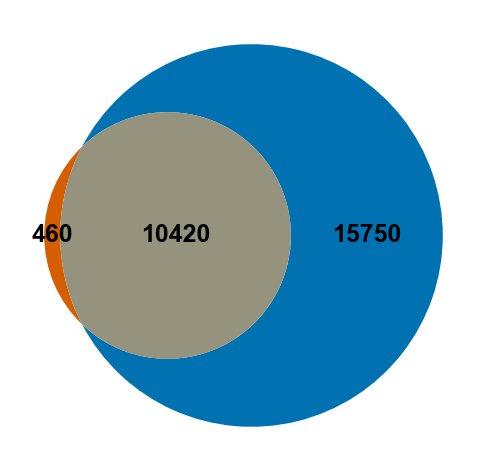

  Exported venn_pepmap_vs_direct_injection_forward.png / .svg

=== Pairwise overlap [forward]: nanoshield_tht021_flip vs direct_injection ===
  only nanoshield_tht021_flip: 1238 | only direct_injection: 10175 | shared: 15995
  only_nanoshield_tht021_flip: 1238 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_only_nanoshield_tht021_flip_forward_peptides.csv
  only_direct_injection: 10175 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_only_direct_injection_forward_peptides.csv
  shared_nanoshield_tht021_flip_direct_injection: 15995 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_shared_nanoshield_tht021_flip_direct_injection_forward_peptides.csv


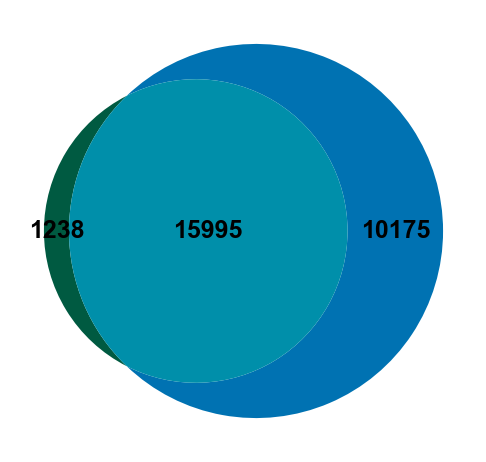

  Exported venn_nanoshield_tht021_flip_vs_direct_injection_forward.png / .svg

=== Pairwise overlap [forward]: pepmap vs nanoshield_tht021_flip ===
  only pepmap: 748 | only nanoshield_tht021_flip: 7101 | shared: 10132
  only_pepmap: 748 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_only_pepmap_forward_peptides.csv
  only_nanoshield_tht021_flip: 7101 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_only_nanoshield_tht021_flip_forward_peptides.csv
  shared_pepmap_nanoshield_tht021_flip: 10132 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_shared_pepmap_nanoshield_tht021_flip_forward_peptides.csv


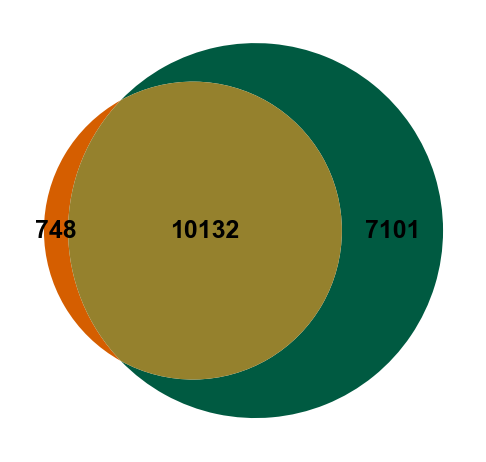

  Exported venn_pepmap_vs_nanoshield_tht021_flip_forward.png / .svg

=== Three-way exclusive sets: pepmap, nanoshield_tht021_flip, direct_injection ===
  only pepmap: 182 | only nanoshield_tht021_flip: 960 | only direct_injection: 9609


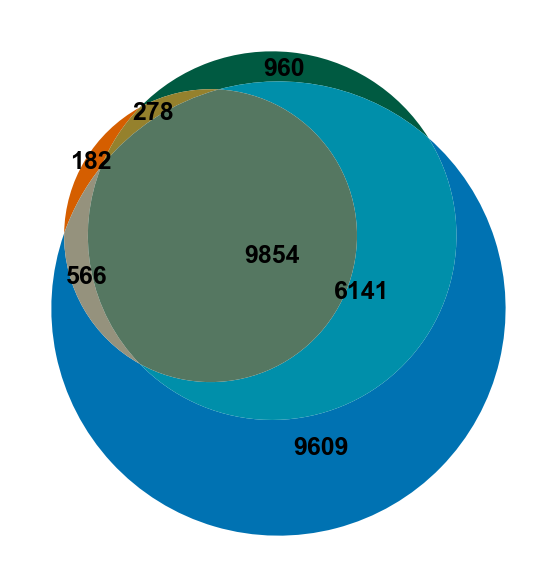

  Exported venn_pepmap_vs_nanoshield_tht021_flip_vs_direct_injection_forward.png / .svg

--- Replicate-vs-replicate overlap [forward] ---
  Condition: pepmap
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1: 16731 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2: 16804 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3: 17099 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4: 16767 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5: 17032 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6: 16819 peptides
  Condition: nanoshield_tht021_flip
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1: 26416 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2: 26923 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3: 25260 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4: 26675 peptide

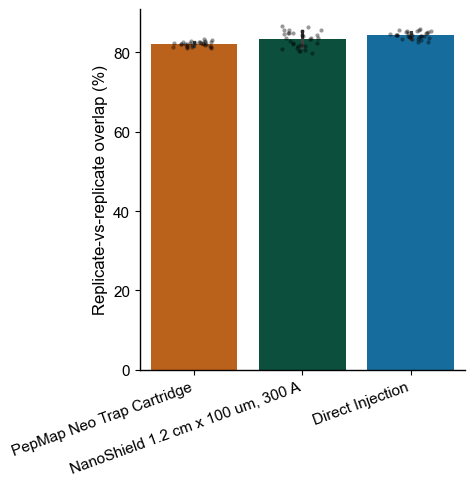

  Exported replicate_overlap_forward.png / .svg

============================== REVERSE FLUSH ==============================
  pepmap: 19538 complete peptides
  nanoshield_tht021_flip: 25899 complete peptides
  direct_injection: 26170 complete peptides
  Exported peptide_list_pepmap_reverse.csv (19538 peptides)
  Exported peptide_list_nanoshield_tht021_flip_reverse.csv (25899 peptides)
  Exported peptide_list_direct_injection_reverse.csv (26170 peptides)

=== Pairwise overlap [reverse]: pepmap vs direct_injection ===
  only pepmap: 1778 | only direct_injection: 8410 | shared: 17760
  only_pepmap: 1778 peptides -> overlap_pepmap_vs_direct_injection_only_pepmap_reverse_peptides.csv
  only_direct_injection: 8410 peptides -> overlap_pepmap_vs_direct_injection_only_direct_injection_reverse_peptides.csv
  shared_pepmap_direct_injection: 17760 peptides -> overlap_pepmap_vs_direct_injection_shared_pepmap_direct_injection_reverse_peptides.csv


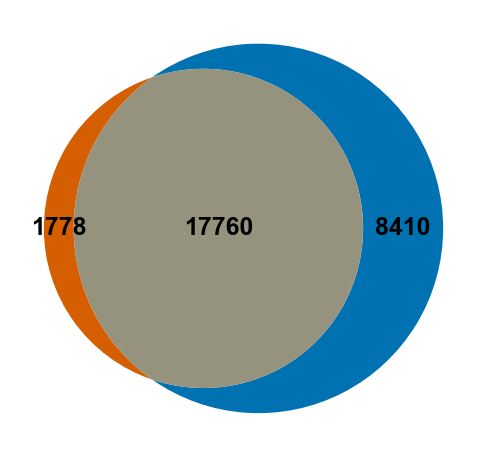

  Exported venn_pepmap_vs_direct_injection_reverse.png / .svg

=== Pairwise overlap [reverse]: nanoshield_tht021_flip vs direct_injection ===
  only nanoshield_tht021_flip: 4357 | only direct_injection: 4628 | shared: 21542
  only_nanoshield_tht021_flip: 4357 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_only_nanoshield_tht021_flip_reverse_peptides.csv
  only_direct_injection: 4628 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_only_direct_injection_reverse_peptides.csv
  shared_nanoshield_tht021_flip_direct_injection: 21542 peptides -> overlap_nanoshield_tht021_flip_vs_direct_injection_shared_nanoshield_tht021_flip_direct_injection_reverse_peptides.csv


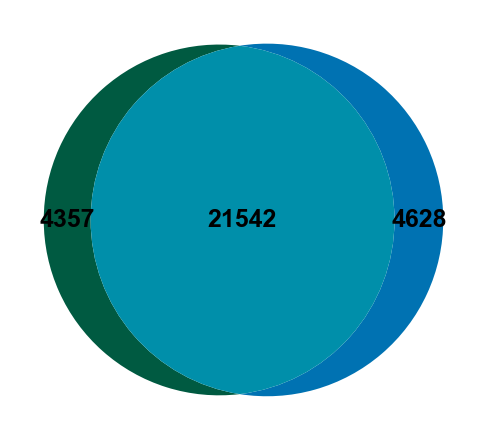

  Exported venn_nanoshield_tht021_flip_vs_direct_injection_reverse.png / .svg

=== Pairwise overlap [reverse]: pepmap vs nanoshield_tht021_flip ===
  only pepmap: 1562 | only nanoshield_tht021_flip: 7923 | shared: 17976
  only_pepmap: 1562 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_only_pepmap_reverse_peptides.csv
  only_nanoshield_tht021_flip: 7923 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_only_nanoshield_tht021_flip_reverse_peptides.csv
  shared_pepmap_nanoshield_tht021_flip: 17976 peptides -> overlap_pepmap_vs_nanoshield_tht021_flip_shared_pepmap_nanoshield_tht021_flip_reverse_peptides.csv


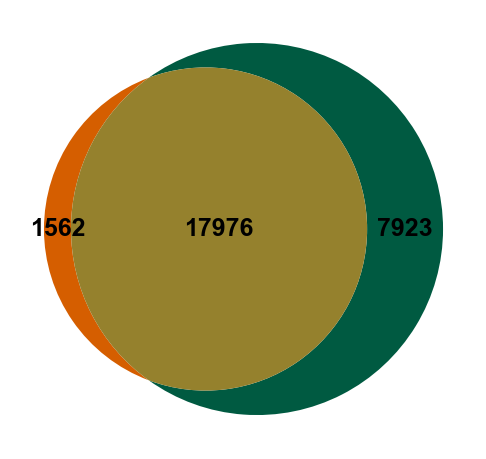

  Exported venn_pepmap_vs_nanoshield_tht021_flip_reverse.png / .svg

=== Three-way exclusive sets: pepmap, nanoshield_tht021_flip, direct_injection ===
  only pepmap: 632 | only nanoshield_tht021_flip: 3211 | only direct_injection: 3698


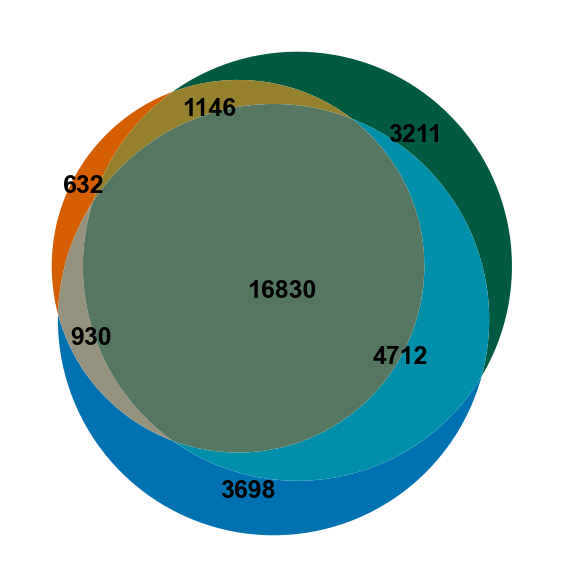

  Exported venn_pepmap_vs_nanoshield_tht021_flip_vs_direct_injection_reverse.png / .svg

--- Replicate-vs-replicate overlap [reverse] ---
  Condition: pepmap
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1: 29828 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2: 29865 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3: 29571 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4: 29655 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5: 30063 peptides
    20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6: 29471 peptides
  Condition: nanoshield_tht021_flip
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1: 37558 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2: 36763 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3: 36981 peptides
    20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4: 37654 peptide

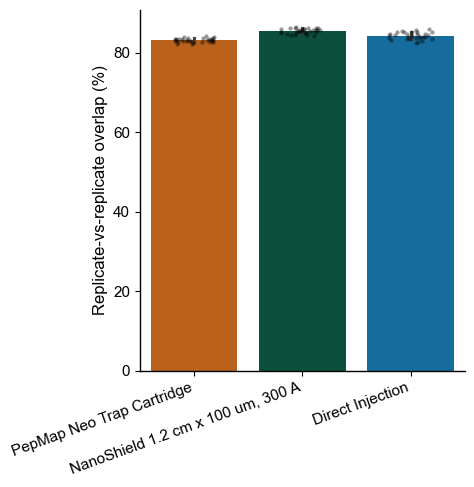

  Exported replicate_overlap_reverse.png / .svg


In [6]:
# overlap analysis - venn diagrams

# define conditions
date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection"
}

conditions = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]
pairwise_comparisons = [
    ("pepmap", "direct_injection"),
    ("nanoshield_tht021_flip", "direct_injection"),
    ("pepmap", "nanoshield_tht021_flip"),
]

peptide_sets_by_flush = {}      # stored for reuse in the GRAVY cell
only_sets_by_flush = {}         # stored for reuse in the GRAVY cell

for flush_label, df_source in [("forward", main_report_pd_fil_for), ("reverse", main_report_pd_fil_rev)]:
    print(f"\n{'='*30} {flush_label.upper()} FLUSH {'='*30}")

    # assign Condition from the acquisition date encoded in the Run name
    df_flush = df_source.copy()
    df_flush["Condition"] = df_flush["Run"].astype(str).str[:8].map(date_to_condition)

    # --- per-condition completeness-filtered peptide sets ---
    peptide_sets = overlap_ana.get_condition_peptide_sets(df_flush, conditions)
    overlap_ana.export_condition_peptide_lists(peptide_sets, output_dir, flush_label)
    peptide_sets_by_flush[flush_label] = peptide_sets

    # --- pairwise overlap + Venn diagrams ---
    for cond_a, cond_b in pairwise_comparisons:
        overlap_ana.compute_pairwise_overlap(peptide_sets, cond_a, cond_b, output_dir, flush_label)
        overlap_ana.plot_venn2(peptide_sets, cond_a, cond_b, output_dir, flush_label)

    # --- three-way exclusive sets (needed for GRAVY comparison, cell below) ---
    only_sets_by_flush[flush_label] = overlap_ana.compute_three_way_only_sets(
        peptide_sets, "pepmap", "nanoshield_tht021_flip", "direct_injection"
    )

    # --- three-way Venn diagram ---
    overlap_ana.plot_venn3(
        peptide_sets, "pepmap", "nanoshield_tht021_flip", "direct_injection", output_dir, flush_label
    )

    # --- replicate-vs-replicate overlap, per condition ---
    print(f"\n--- Replicate-vs-replicate overlap [{flush_label}] ---")
    replicate_overlap_frames = []
    for cond in conditions:
        print(f"  Condition: {cond}")
        sets_by_run = overlap_ana.get_replicate_peptide_sets(df_flush, cond)
        rep_overlap_df = overlap_ana.compute_pairwise_replicate_overlap(sets_by_run, cond)
        replicate_overlap_frames.append(rep_overlap_df)

    replicate_overlap_all = pd.concat(replicate_overlap_frames, ignore_index=True)
    overlap_ana.export_replicate_overlap_table(replicate_overlap_all, output_dir, flush_label)
    overlap_ana.plot_replicate_overlap_bar(replicate_overlap_all, output_dir, flush_label)


============================== FORWARD FLUSH — GRAVY ==============================
  Exported gravy_exclusive_peptides_forward.csv (10751 rows)

  GRAVY summary statistics [forward]:
             Condition    N   Mean    SD  Median     Q1    Q3    Min   Max
                pepmap  182 -0.103 0.769  -0.069 -0.626 0.400 -2.600 1.488
nanoshield_tht021_flip  960 -0.477 0.968  -0.435 -1.093 0.217 -3.550 2.056
      direct_injection 9609 -0.331 0.828  -0.311 -0.885 0.244 -3.388 2.444


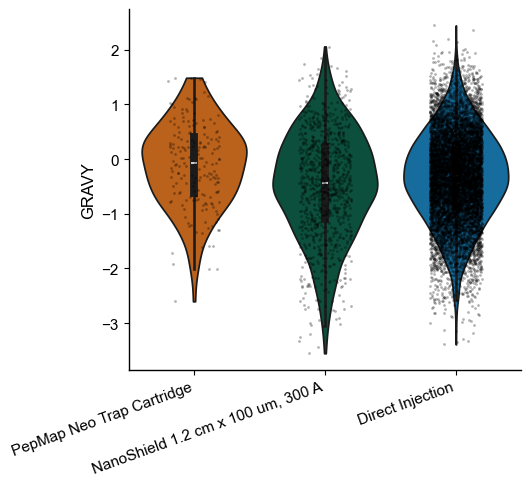

  Exported gravy_exclusive_peptides_quickview_forward.png / .svg

============================== REVERSE FLUSH — GRAVY ==============================
  Exported gravy_exclusive_peptides_reverse.csv (7541 rows)

  GRAVY summary statistics [reverse]:
             Condition    N   Mean    SD  Median     Q1    Q3    Min   Max
                pepmap  632 -0.257 0.764  -0.200 -0.729 0.239 -2.886 1.875
nanoshield_tht021_flip 3211 -0.511 0.859  -0.475 -1.084 0.083 -3.271 2.330
      direct_injection 3698 -0.205 0.817  -0.173 -0.747 0.380 -3.175 2.444


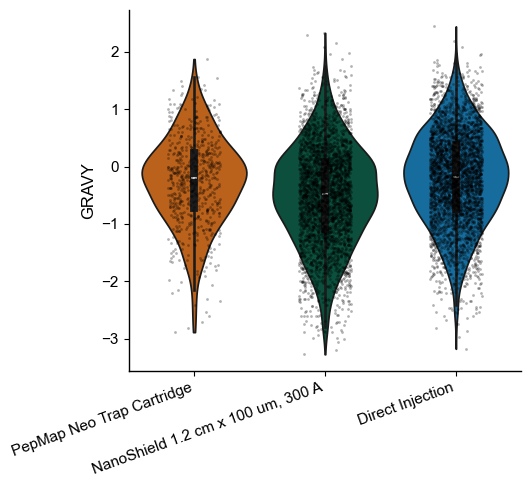

  Exported gravy_exclusive_peptides_quickview_reverse.png / .svg


In [7]:
# overlap analysis - gravy distributions

for flush_label, only_sets in only_sets_by_flush.items():
    print(f"\n{'='*30} {flush_label.upper()} FLUSH — GRAVY {'='*30}")
    gravy_df = overlap_ana.build_gravy_table(only_sets, flush_label)
    overlap_ana.export_gravy_table(gravy_df, output_dir, flush_label)
    overlap_ana.print_gravy_summary_stats(gravy_df, flush_label)
    overlap_ana.plot_gravy_distribution(gravy_df, output_dir, flush_label)

In [8]:
# overlap analysis - gravy pairwise statistics

gravy_ttest_frames = []

for flush_label, only_sets in only_sets_by_flush.items():
    gravy_df = overlap_ana.build_gravy_table(only_sets, flush_label)
    ttest_df = overlap_ana.run_gravy_pairwise_ttests(gravy_df, flush_label)
    gravy_ttest_frames.append(ttest_df)

gravy_ttest_all = pd.concat(gravy_ttest_frames, ignore_index=True)
gravy_ttest_all.to_csv(output_dir / "gravy_pairwise_ttests.csv", index=False)
print(f"Exported gravy_pairwise_ttests.csv")

=== FORWARD ===
pepmap: n=182, mean=-0.1034, median=-0.0691, SD=0.7690
nanoshield_tht021_flip: n=960, mean=-0.4774, median=-0.4345, SD=0.9682
direct_injection: n=9609, mean=-0.3314, median=-0.3111, SD=0.8281
  pepmap vs nanoshield_tht021_flip: t=5.753, p=2.152e-08
  pepmap vs direct_injection: t=3.957, p=1.074e-04
  nanoshield_tht021_flip vs direct_injection: t=-4.510, p=7.175e-06

=== REVERSE ===
pepmap: n=632, mean=-0.2574, median=-0.2000, SD=0.7641
nanoshield_tht021_flip: n=3211, mean=-0.5110, median=-0.4750, SD=0.8587
direct_injection: n=3698, mean=-0.2054, median=-0.1732, SD=0.8165
  pepmap vs nanoshield_tht021_flip: t=7.466, p=1.838e-13
  pepmap vs direct_injection: t=-1.566, p=1.177e-01
  nanoshield_tht021_flip vs direct_injection: t=-15.093, p=1.226e-50

Exported gravy_pairwise_ttests.csv
